# Notebook 2: Herding without an end goal (SARSA)

#### **What changes?**
In the previous notebook the pen was in a corner, and an episode ended as soon as the sheep was in the pen. Now the **pen is in the middle of the field and it is open on all sides**. The sheep can walk in, but it can also walk out again. So the task is not "get the sheep in" anymore, but "**get the sheep in and keep it there**".

The dogs get a reward of +1 for every step the sheep is in the pen, and -0.1 for every step it is outside. There is **no end of an episode**: the task just continues. This is called a *continuing task*.

Every 300 steps a new sheep arrives somewhere random on the field (the old one is taken away). This is not the end of an episode: the dogs keep learning as usual. We do this so the dogs also get practice in fetching a sheep from far away, not only in guarding a sheep that is already in. So we make a distinction between a terminal episode and a reset like this.

The **sheep** is the same as in notebook 1. The sheep has a parameter `sheep_panic`. When a dog comes close, the sheep sometimes panics (`sheep_panic` is the chance that this happens). When it panics, it either sprints 2 cells away instead of 1, or it acts randomly (sprint or random is a flip of a coin, 50%). With `sheep_panic = 0` the sheep is calm. Note that this is a property of the sheep only: it says nothing about how many dogs there are.

#### **Why not Monte Carlo?**
Monte Carlo learning waits until the end of an episode to compute the return. Here there is no end, so Monte Carlo can never learn. We need a method that learns **every step**.

#### **SARSA**
SARSA does not wait for the real return. After every step it makes a guess of the return: the reward it just got, plus what it *expects* from the next state. The name comes from the five things it uses: **S**tate, **A**ction, **R**eward, next **S**tate, next **A**ction.

\begin{equation}
Q(s, a) \leftarrow Q(s, a) + \alpha \, \big(r + \gamma Q(s', a') - Q(s, a)\big)
\end{equation}

The part between brackets is the **TD error** (temporal difference error): what we got plus what we now expect, minus what we expected before. Using your own estimate Q(s', a') instead of the real future is called *bootstrapping*: one real step, then an estimate of the rest.

Note that a' is the action the dog will **actually** do next (chosen with $\epsilon$-greedy, so sometimes random). So SARSA is **on-policy**, just like our Monte Carlo dogs: it learns the value of the behaviour it is actually following, exploration included.

#### **Ends, limits and resets: what is the difference?**
* A **terminal state** is a real end of the task: the sheep is in the corner pen (notebook 1). After it, nothing follows.
* A **time limit** (like the 200 steps in notebook 1) is our own choice, to stop an episode that takes too long. Monte Carlo has to treat it as a real terminal end, because it can only learn when an episode is over.
* A **reset** (like a new sheep every 300 steps in this notebook) only puts things back at a random place. Nothing ends.

Monte Carlo needs episodes that end (by a terminal state or a time limit). SARSA does not need episodes at all: it learns every step, and it just continues through a reset as if nothing happened. That is why SARSA works for a task that never ends.

#### **What does a dog see?**
Same as before: the position of the sheep (x, y), and where the sheep is relative to the dog (dx, dy, cut off at 3 cells). A dog does **not** see the other dog.

#### **Measuring success**
Without episodes we cannot count successes. Instead we measure the **share of time the sheep is in the pen** (over the last 10,000 steps).

So remember we have the following components:
* Number of dogs (1 or 2)
* Whether the sheep panics
* Learning rate $\alpha$, discount $\gamma$, exploration $\epsilon$
* How often a new sheep arrives
* Number of training steps

# Lets get started

In [1]:
import mesa
from mesa.discrete_space import OrthogonalMooreGrid, CellAgent
from mesa.visualization import SolaraViz
import solara
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import deque
import copy

# the five things a dog can do: stay, right, left, up, down (as steps in x and y)
ACTIONS = [(0, 0), (1, 0), (-1, 0), (0, 1), (0, -1)]

# Agent setup: the sheep (rule-based, same as notebook 1)

In [2]:
class Sheep(CellAgent):
    """A rule-based sheep that flees from dogs.
    flee_radius: how close a dog must be before the sheep reacts
    sheep_panic: chance that a fleeing sheep panics and sprints 2 cells away instead of 1
                 (0 = calm sheep, higher = panics more easily)

    The sheep does not learn. It follows the same simple rules every step:
      1. a dog is close  -> flee (and sometimes panic and sprint)
      2. no dog is close -> mostly graze (stay put), sometimes wander a bit
    It is a CellAgent: it lives on a cell of the grid, and moves by switching to another cell.
    """
    def __init__(self, model, cell, flee_radius=2, sheep_panic=0.0):
        super().__init__(model)
        self.cell = cell                  # the cell the sheep starts on
        self.flee_radius = flee_radius
        self.sheep_panic = sheep_panic

    def distance_to_nearest_dog(self, position):
        """Distance (in steps, diagonal counts as one step) from a position to the nearest dog.

        We measure the distance as the largest of the x-distance and the y-distance
        (this is called the Chebyshev distance). So a dog 2 cells to the right and 1 cell up
        is at distance 2: it is within reach in 2 diagonal-ish steps.
        """
        # the positions of all dogs, as (x, y) coordinates
        dog_positions = [dog.cell.coordinate for dog in self.model.dogs]
        # for every dog: the distance to the position. Then take the smallest: the nearest dog
        return min(max(abs(position[0] - dx), abs(position[1] - dy)) for dx, dy in dog_positions)

    def step(self):
        x, y = self.cell.coordinate
        # where could the sheep go? (stay, or one step in four directions, but not off the field)
        # ACTIONS are the same five moves the dogs have: stay, right, left, up, down
        options = [(x + ax, y + ay) for ax, ay in ACTIONS if self.model.inside((x + ax, y + ay))]

        if self.distance_to_nearest_dog((x, y)) <= self.flee_radius:
            # a dog is close: flee.
            # for every option, how far would we be from the nearest dog? Find the biggest distance...
            best = max(self.distance_to_nearest_dog(p) for p in options)
            # ...and pick one of the options with that distance (at random, if there are several)
            target = self.model.random.choice([p for p in options if self.distance_to_nearest_dog(p) == best])
            # panic: sometimes the sheep sprints one cell further in the same direction.
            # (target - current position) is the step the sheep takes; adding it twice gives a 2-cell sprint
            if self.model.random.random() < self.sheep_panic:
                # 50% percent it sprints, 50% it just flees randomly.
                if self.model.random.random() < 0.5:
                    jump = (2 * target[0] - x, 2 * target[1] - y) # the cell 2 steps away in the same direction
                else:
                    jump = self.model.random.choice(options)      # just flee randomly
                if self.model.inside(jump):                   # only if the sprint stays on the field
                    target = jump
        elif self.model.random.random() > 0.2:
            target = (x, y)                                   # no dog close: mostly graze (stay put, 80% of the time)
        else:
            target = self.model.random.choice(options)        # and sometimes wander a bit (20% of the time)

        # move the sheep to its new cell
        self.cell = self.model.grid[target]

# Agent setup: the dog (SARSA)
The order of things is a bit different from Monte Carlo. A SARSA dog always *already knows* what it is going to do next, because it needs that next action (a') for its update. So:
* `move()`: do the action that was chosen before
* then the sheep reacts, and the model hands out the reward
* `learn(reward)`: look at the new state s', choose the next action a', update Q(s, a) with the TD error, and then s' and a' become the new s and a

The dog does **not** need a memory of the whole episode anymore (like the Monte Carlo dog): it only needs to remember the last state and action.

In [3]:
class Dog(CellAgent):
    """A dog that learns to herd with SARSA.
    alpha: learning rate (how far we move a Q-value when we learn something new)
    gamma: discount (how much we care about rewards further in the future)
    epsilon: exploration (how often we pick a random action instead of the best one)

    How a SARSA dog works (every step):
      move with the action a that we chose before (in state s),
      see what happens (reward r, new state s'), choose the next action a',
      and update Q(s, a) right away, using r + gamma x Q(s', a').
    So unlike the Monte Carlo dog, it learns DURING the task, after every single step.
    """
    def __init__(self, model, cell, alpha=0.1, gamma=0.95, epsilon=0.1):
        super().__init__(model)
        self.cell = cell                  # the cell the dog starts on
        self.alpha = alpha
        self.gamma = gamma
        self.epsilon = epsilon
        self.learning = True    # we can switch learning off (e.g., to test a trained dog)

        # The Q-table: a dictionary from state to an array with one value per action (5 actions).
        # Q[s][a] = how much reward the dog expects in the long run if it does action a in state s.
        # It starts empty and fills up as the dog meets new states.
        self.Q = {}

        # SARSA needs to know the state s it was in AND the action a it chose there.
        # Both are filled in at the very first step. 
        # Note!!! No memory of a whole episode needed, it can just update incrementally!
        self.state = None       # the state s we were in when we chose our action
        self.action = None      # the action a we chose in s (an index into ACTIONS)

    def observe(self):
        """The state: where is the sheep on the field, and where is the sheep relative to me?

        The state is a tuple of 4 numbers, e.g. (5, 2, -1, 3) means:
          the sheep is at x=5, y=2, and it is 1 cell to my left and 3 (or more) cells above me.
        Note: this always looks at the world as it is RIGHT NOW. Called before the sheep moves,
        it gives s; called after the sheep moved (in learn), it gives s'.
        """
        sx, sy = self.model.sheep.cell.coordinate     # where the sheep is
        x, y = self.cell.coordinate                   # where I am
        # relative position is cut off at 3 cells (np.clip keeps a number between -3 and 3):
        # "far to the right" is all the same to the dog. This keeps the number of states small
        return (sx, sy, int(np.clip(sx - x, -3, 3)), int(np.clip(sy - y, -3, 3)))

    def q_values(self, state):
        """Look up the Q values of a state. A state we have never seen starts at 0 for every action."""
        if state not in self.Q:
            self.Q[state] = np.zeros(len(ACTIONS))
        return self.Q[state]

    def choose(self, state):
        """Epsilon-greedy: usually the best action so far, sometimes a random one."""
        if self.model.random.random() < self.epsilon:
            return self.model.random.randrange(len(ACTIONS))     # explore: random action
        q = self.q_values(state)                                 # exploit: best action so far
        # np.flatnonzero(q == q.max()) gives ALL actions with the highest value;
        # we pick one of those at random, so ties (e.g. all zeros in a new state) are broken fairly
        return self.model.random.choice(np.flatnonzero(q == q.max()).tolist())

    def move(self):
        """Do the action we chose before."""
        # very first step: we have not chosen anything yet, so we observe and choose now.
        # after that, the action was already chosen at the end of the previous step (in learn()),
        # because SARSA needs to know its next action in advance
        if self.state is None:
            self.state = self.observe()
            self.action = self.choose(self.state)
        # do the move: ACTIONS[action] is a step in x and y, e.g. (1, 0) = one step to the right
        x, y = self.cell.coordinate
        new_position = (x + ACTIONS[self.action][0], y + ACTIONS[self.action][1])
        if self.model.inside(new_position): # dogs cannot leave the field, so we only update if the new position is still on the field
            self.cell = self.model.grid[new_position]

    def learn(self, reward):
        """The SARSA update, using S, A, R, S', A'.
        reward: the shared reward of this step (R)

        When this runs, the dogs and the sheep have already moved. self.state is a stored snapshot:
        it does NOT change when the world changes, only when we assign a new value to it
        (on the last line of this method). So here:
          self.state, self.action = s and a: the snapshot from BEFORE the move, and what we did
          next_state, next_action = s' and a': a new snapshot from AFTER the move, and what we will do
        We update Q(s, a), the step we just took, using the real reward plus our own
        estimate Q(s', a') for the rest of the future (this is called bootstrapping).
        """
        # S': where are we now, after the move?
        next_state = self.observe()
        # A': what will we do next? We really will do this action in the next step.
        # That is what makes SARSA "on-policy": it learns about the behaviour it actually follows,
        # including the random exploration moves
        next_action = self.choose(next_state)

        if self.learning: # only update the Q-table if we are still learning (not frozen)
            q = self.q_values(self.state) # the Q-values of s: the state BEFORE the move (not the current one!)
            # the target: the reward we just got + the discounted value of what we will do next.
            # (there is no "if done" here: in this task nothing ever ends, so there is always a future)
            target = reward + self.gamma * self.q_values(next_state)[next_action]
            # TD error = target - what we expected before.
            # we move our estimate a small step (alpha) towards the target
            q[self.action] += self.alpha * (target - q[self.action])

        # The update is done. Now we slide one step forward: s' and a' become the new s and a.
        # In the next model step, move() does action a' (no need to observe again, nothing has moved).
        # Think of a sliding window over the chain s0, a0, r1, s1, a1, r2, s2, ...:
        # every step we update the first pair in the window, then shift the window by one.
        self.state, self.action = next_state, next_action

# Model setup
One model step is: the dogs move, the sheep reacts, the model hands out the reward, and the dogs learn. Every `new_sheep_every` steps the sheep is placed somewhere random (outside the pen), but the learning just continues.

The datacollector collects every step (the batch runner needs that). We also keep a `block_log`: every 5,000 steps we write down the share of time the sheep was in the pen. We use that for the learning curves.

In [4]:
class HerdingModel(mesa.Model):
    """The herding model with the pen in the middle: one sheep, one or two learning dogs.

    n_dogs: number of dogs (1 or 2)
    sheep_panic: chance that the fleeing sheep panics (0 = calm sheep)
    size: the field is size x size cells
    new_sheep_every: every so many steps a new sheep arrives at a random place (this is NOT an episode end)
    flee_radius: how close a dog must be before the sheep reacts
    alpha, gamma, epsilon: the learning parameters, passed on to every dog
    """
    def __init__(self, n_dogs=1, sheep_panic=0.0, size=8, new_sheep_every=300,
                 flee_radius=2, alpha=0.1, gamma=0.95, epsilon=0.1, rng=None):
        super().__init__(rng=rng)
        self.size = size
        self.new_sheep_every = new_sheep_every
        # the field: a grid of size x size cells. torus=False means the edges are walls
        self.grid = OrthogonalMooreGrid((size, size), torus=False, random=self.random)
        # the pen is the 2 x 2 square in the middle of the field. pen_low is its lower-left corner
        # (with size=8: x and y are 3 or 4)
        self.pen_low = size // 2 - 1

        # create the sheep and the dogs (at random places outside the pen)
        self.sheep = Sheep(self, self.random_cell(), flee_radius=flee_radius, sheep_panic=sheep_panic)
        # create_agents makes n_dogs dogs at once, each on its own random cell.
        # self.dogs is an AgentSet: a group of agents we can tell to do something together (e.g. self.dogs.do("move"))
        self.dogs = Dog.create_agents(self, n_dogs, [self.random_cell() for _ in range(n_dogs)],
                                      alpha=alpha, gamma=gamma, epsilon=epsilon)

        # bookkeeping
        self.t = 0                                   # total number of steps (there are no episodes)
        self.recent_in_pen = deque(maxlen=10_000)    # was the sheep in the pen? (last 10,000 steps; older ones drop out)
        self.in_pen_share = 0                        # share of the last 10,000 steps the sheep was in the pen
        self.block = []                              # in-pen values of the current block of 5,000 steps
        self.block_log = []                          # one row per block of 5,000 steps, for the learning curves

        # Data collection!
        # The datacollector runs every step (the batch runner of our Mesa version needs that).
        # It only reads an attribute that is updated every 5,000 steps.
        self.datacollector = mesa.DataCollector(
            model_reporters={"in_pen_share": "in_pen_share"}
        )

    def inside(self, position):
        """Is this position on the field? (used by the dogs and the sheep, so nobody walks off)"""
        return 0 <= position[0] < self.size and 0 <= position[1] < self.size

    def in_pen(self, position):
        """Is this position in the pen (the 2 x 2 square in the middle)?"""
        return (self.pen_low <= position[0] <= self.pen_low + 1) and (self.pen_low <= position[1] <= self.pen_low + 1)

    def random_cell(self):
        """A random cell that is not in the pen. We need this for the positions of the sheep and the dogs.
        We keep drawing random positions until we find one outside the pen."""
        while True:
            position = (self.random.randrange(self.size), self.random.randrange(self.size))
            if not self.in_pen(position):
                return self.grid[position]

    def step(self):
        """One model step: the dogs move, the sheep reacts, reward, and the dogs learn."""
        self.dogs.do("move")          # every dog does the action it chose before
        self.sheep.step()             # the sheep reacts
        self.t += 1

        # reward: +1 if the sheep is in the pen, -0.1 if not
        sheep_in = self.in_pen(self.sheep.cell.coordinate)
        reward = 1.0 if sheep_in else -0.1        # shared reward: all dogs get the same

        # bookkeeping for the measures
        self.recent_in_pen.append(sheep_in)
        self.block.append(sheep_in)
        if len(self.block) == 5_000:              # every 5,000 steps: one point for the learning curve
            self.block_log.append({"step": self.t, "in_pen_share": np.mean(self.block)})
            self.block = []
            self.in_pen_share = np.mean(self.recent_in_pen)   # True/False counts as 1/0

        # now and then a new sheep arrives (this is NOT the end of an episode, learning just continues)
        if self.t % self.new_sheep_every == 0:
            self.sheep.cell = self.random_cell()

        self.dogs.do("learn", reward)  # every dog does its SARSA update
        self.datacollector.collect(self)   # every step (the batch runner needs this)

# Lets train some dogs
We train four set-ups for 1,500,000 steps each and look at the learning curves: how much of the time is the sheep in the pen? (This takes about 10 minutes.)

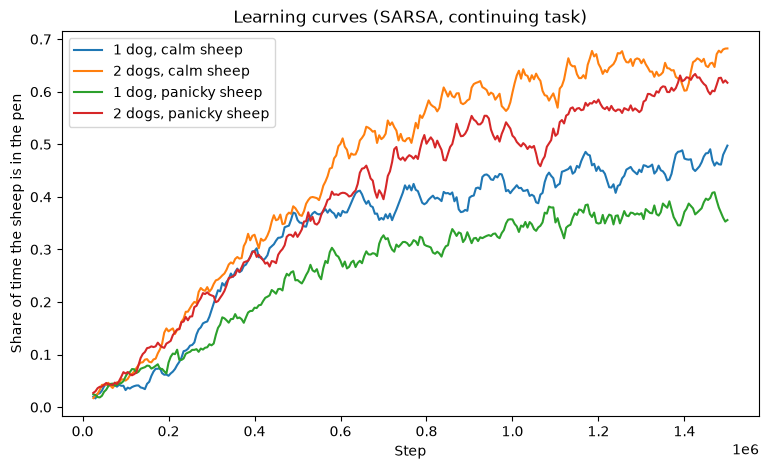

1 dog, calm sheep        share of time in pen (last 10,000 steps): 0.50
2 dogs, calm sheep       share of time in pen (last 10,000 steps): 0.66
1 dog, panicky sheep     share of time in pen (last 10,000 steps): 0.36
2 dogs, panicky sheep    share of time in pen (last 10,000 steps): 0.64


In [5]:
def train(n_steps=1_500_000, **params):
    """Make a model and run it for n_steps steps. Returns the trained model.
    There are no episodes here: the model just runs for n_steps steps."""
    model = HerdingModel(**params)
    for _ in range(n_steps):
        model.step()
    return model

conditions = {
    "1 dog, calm sheep":     dict(n_dogs=1, sheep_panic=0.0),
    "2 dogs, calm sheep":    dict(n_dogs=2, sheep_panic=0.0),
    "1 dog, panicky sheep":  dict(n_dogs=1, sheep_panic=0.6),
    "2 dogs, panicky sheep": dict(n_dogs=2, sheep_panic=0.6),
}
# Train all four conditions (this takes a while, because each model runs for 1,500,000 steps)
trained = {name: train(rng=1, **params) for name, params in conditions.items()}

# plot the learning curves: share of time in the pen per block of 5,000 steps (rolling mean of 5 blocks)
fig, ax = plt.subplots(figsize=(9, 5))
for name, model in trained.items():
    df = pd.DataFrame(model.block_log)
    ax.plot(df["step"], df["in_pen_share"].rolling(5).mean(), label=name)
ax.set_xlabel("Step")
ax.set_ylabel("Share of time the sheep is in the pen")
ax.set_title("Learning curves (SARSA, continuing task)")
ax.legend()
plt.show()

for name, model in trained.items():
    print(f"{name:24s} share of time in pen (last 10,000 steps): {model.in_pen_share:.2f}")

# Make a custom visualization so we can watch the trained dogs
We pass a *trained* model to SolaraViz, so press play (not reset: reset makes a new, untrained model). We freeze learning and set exploration low (5%), so we see what the dogs have learned.

In [6]:
from matplotlib.patches import Rectangle

@solara.component
def HerdingVisualization(model):
    from mesa.visualization.components.matplotlib_components import update_counter
    update_counter.get()  # re-render when the model steps
    fig = plt.Figure(figsize=(6, 6))
    ax = fig.subplots()
    s, p = model.size, model.pen_low
    ax.add_patch(Rectangle((0, 0), s, s, facecolor="yellowgreen", alpha=0.3))     # the field
    ax.add_patch(Rectangle((p, p), 2, 2, facecolor="saddlebrown", alpha=0.4))     # the pen (in the middle)
    x, y = model.sheep.cell.coordinate
    ax.scatter(x + 0.5, y + 0.5, s=600, c="white", edgecolors="black", zorder=10)  # the sheep
    for i, dog in enumerate(model.dogs):                                            # the dogs
        dx, dy = dog.cell.coordinate
        ax.scatter(dx + 0.5, dy + 0.5, s=300, c=["black", "tab:orange"][i % 2], marker="s", zorder=10)
    ax.set_xlim(0, s)
    ax.set_ylim(0, s)
    ax.set_aspect("equal")
    ax.set_xticks(range(s + 1))
    ax.set_yticks(range(s + 1))
    ax.grid(True, alpha=0.3)
    ax.set_title(f"Step {model.t}")
    solara.FigureMatplotlib(fig)

model = trained["2 dogs, calm sheep"]   # try the other conditions too
for dog in model.dogs:
    dog.epsilon = 0.05      # explore a little less, so we mostly see what they learned
    dog.learning = False    # freeze: they keep acting, but stop updating their Q-tables

page = SolaraViz(model, components=[HerdingVisualization], name="Herding with SARSA")
page

Cannot show ipywidgets in text

# Batch run
All four set-ups, one run each (this already takes about 10 minutes; set `iterations=2` or more if you have time). We look at the share of time the sheep is in the pen at the end of training.

  0%|          | 0/4 [00:00<?, ?it/s]

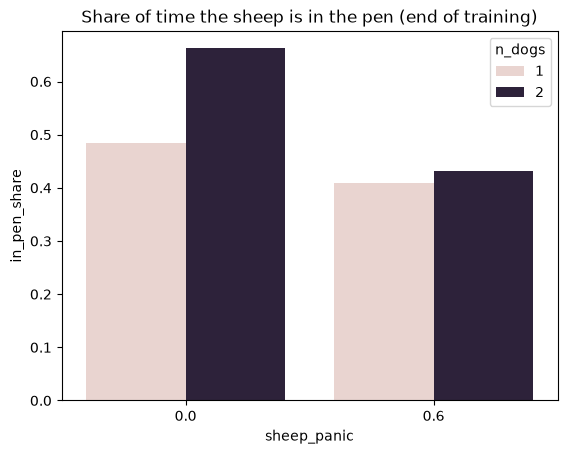

In [7]:
params = {"n_dogs": [1, 2],
          "sheep_panic": [0.0, 0.6]}

results = mesa.batch_run(
    HerdingModel,
    parameters=params,
    iterations=1,               # one run per condition (more runs = more reliable, but slower)
    max_steps=1_500_000,
    number_processes=1,
    data_collection_period=-1,  # only collect at the end of the run
    display_progress=True,
)
results = pd.DataFrame(results)
results.to_csv("./herding_sarsa_batch_run.csv")

sns.barplot(results, x="sheep_panic", y="in_pen_share", hue="n_dogs")
plt.title("Share of time the sheep is in the pen (end of training)")
plt.show()

# Experiments for you
1. **Why two dogs now?** In the corner pen (notebook 1), a second dog did not help. Here it does, with a calm sheep. Watch the visualization: what goes wrong with one dog, and what are the two dogs doing that one dog cannot?
2. **Panic.** With a panicky sheep, does a second dog still help? Remember that a panicking sheep sometimes sprints away and sometimes moves randomly. Can more dogs help against randomness? Try changing the 50% in the sheep's `step()`: what if a panicking sheep always sprints?
3. **Discount in a continuing task.** There is no end, so the return is an infinite sum. Why does that only work with $\gamma < 1$? Try $\gamma = 0.5$ and $\gamma = 0.99$. What changes in the behaviour of the dogs?
4. **New sheep.** Set `new_sheep_every` to a very large number (e.g., 10 million, so it never happens). What do the dogs learn now, and what do they *not* learn? Hint: what happens when the sheep wanders far away?
5. **Exploration.** On-policy learning takes its own exploration into account. A dog that explores a lot may learn to stay a bit further away from the pen. Why? Try $\epsilon = 0.3$.
6. **Learning every step vs at the end.** Compare the learning speed with notebook 1 (Monte Carlo). Which one learns faster, and why?